In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pylabdd as dd
from matplotlib.gridspec import GridSpec
print(f'pyLabDD version {dd.__version__}')

# plot function for stress and pile-up dislocations
def plot_stress_bfield(npt = 300, file=None, cutoff=100., fs=(12, 9)):
    xmid = dsl.lx*0.5
    xpts = np.linspace(0.0, dsl.lx, npt) - xmid
    ypts = np.linspace(0.0, dsl.ly, npt)
    XP, YP = np.meshgrid(xpts, ypts)
    s12 = np.zeros((npt, npt), dtype=np.float64)
    for i in range(dsl.Ntot):
        s12 += dsl.bx[i] * dsl.sig_xy(XP - dsl.xpos[i] + xmid, YP - dsl.ypos[i])
        s12 -= dsl.by[i] * dsl.sig_xy(YP - dsl.ypos[i], XP - dsl.xpos[i] + xmid)
    extent = (-xmid, xmid, 0.0, dsl.ly)
    
    #fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(4, 12), gridspec_kw={"height_ratios": [4, 1]}, sharex=True)
    fig = plt.figure(figsize=fs)
    gs = GridSpec(2, 1, height_ratios=[3, 1], hspace=0.0)
    # -----------------------------
    # upper plot: stress field and dislocations
    # -----------------------------
    ax1 = fig.add_subplot(gs[0])
    #ax1.xaxis.set_label_position('top')
    #ax1.set_xlabel(r"x ($\mu$m)")
    ax1.xaxis.tick_top()
    plt.setp(ax1.get_xticklabels(), visible=False)
    ax1.set_ylabel(r"y ($\mu$m)")
    im = ax1.imshow(s12, origin="lower", extent=extent,
        vmin=-cutoff, vmax=cutoff, cmap=plt.cm.RdBu, aspect="equal")
    ax1.scatter(dsl.xpos[:npu] - xmid, dsl.ypos[:npu], s=10, c="yellow", marker="o")
    #cbar = fig.colorbar(im, ax=ax1, pad=0.15)
    #cbar.set_label(r"$\sigma_{12}$ (MPa)")
    
    # -----------------------------
    # Lower Plot: b-field
    # -----------------------------
    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.plot(dsl.xpos[npu:] - xmid, dsl.by[npu:], lw=2)  #color=plt.cm.viridis(0)
    ax2.set_xlim(ax1.get_xlim())
    yl1 = dsl.by[npu:].min() * 1.05
    yl2 = dsl.by[npu:].max() * 1.05
    ax2.set_ylim(yl1, yl2)
    pos1 = ax1.get_position()
    pos2 = ax2.get_position()
    if yl1 >= 0:
        ax2.invert_yaxis()
        p2 = pos1.y1# + pos2.height
    else:
        p2 = pos1.y0 - pos2.height
    ax2.set_position([
        pos1.x0,
        p2, #-0.1,
        pos1.width,
        pos2.height
    ])
    ax2.set_ylabel(r"$b \, / \, B$")
    ax2.set_xlabel(r"x ($\mu$m)")
    ax2.yaxis.set_label_position('right')
    ax2.yaxis.tick_right()
    cax = fig.add_axes([pos1.x1 + 0.02,
                        pos1.y0 + 0.03,
                        0.02,
                        pos1.y1 - pos1.y0 - 0.03]) 
    cbar = fig.colorbar(im, cax=cax)
    cbar.ax.set_title(r"$\sigma_{12}$ (MPa)")
    if file is not None:
        plt.savefig(file, dpi=300)
    plt.show()

pyLabDD version 1.3.2


In [3]:
# Read data from file if avaiable
gbdd = dd.GB_dislocations(from_file="pu1_T500_H01_L10.h5")

Simulation with N_gbn=201, grain_size=0.01, dtmax=0.001
Set drag: 1000000.0
Set fcrit: 1000000000.0
Set Qact: 95000.0
 Conducting simulation with Npu preexisting dislocations: Npu =           1
 and Nabs absorbed dislocations: Nabs =           0
 Conducting simulation with static PU dislocations as drag>1.e5
 Starting iteration for T, tau0, D2, Lgb, Ngbn   1200.0000000000000        1.0000000000000000E-004   1.0000000000000000E-002   1.0000000000000000              201
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)      500000   1.0000000000000000E-003   4.9789558249467363E-004   1.1947110671934782E-009   4.6679282507432288E-005           1           0   5.0000000000000001E-003
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, max(y)     1000000   1.0000000000000000E-003   9.9789558248285031E-004   4.0162286992179387E-010   2.5969307927836409E-005           1           0   5.0000000000000001E-003
 Iteration, dt, ttot(s), max(bdot), sum(bfield), Npu, Nabs, m

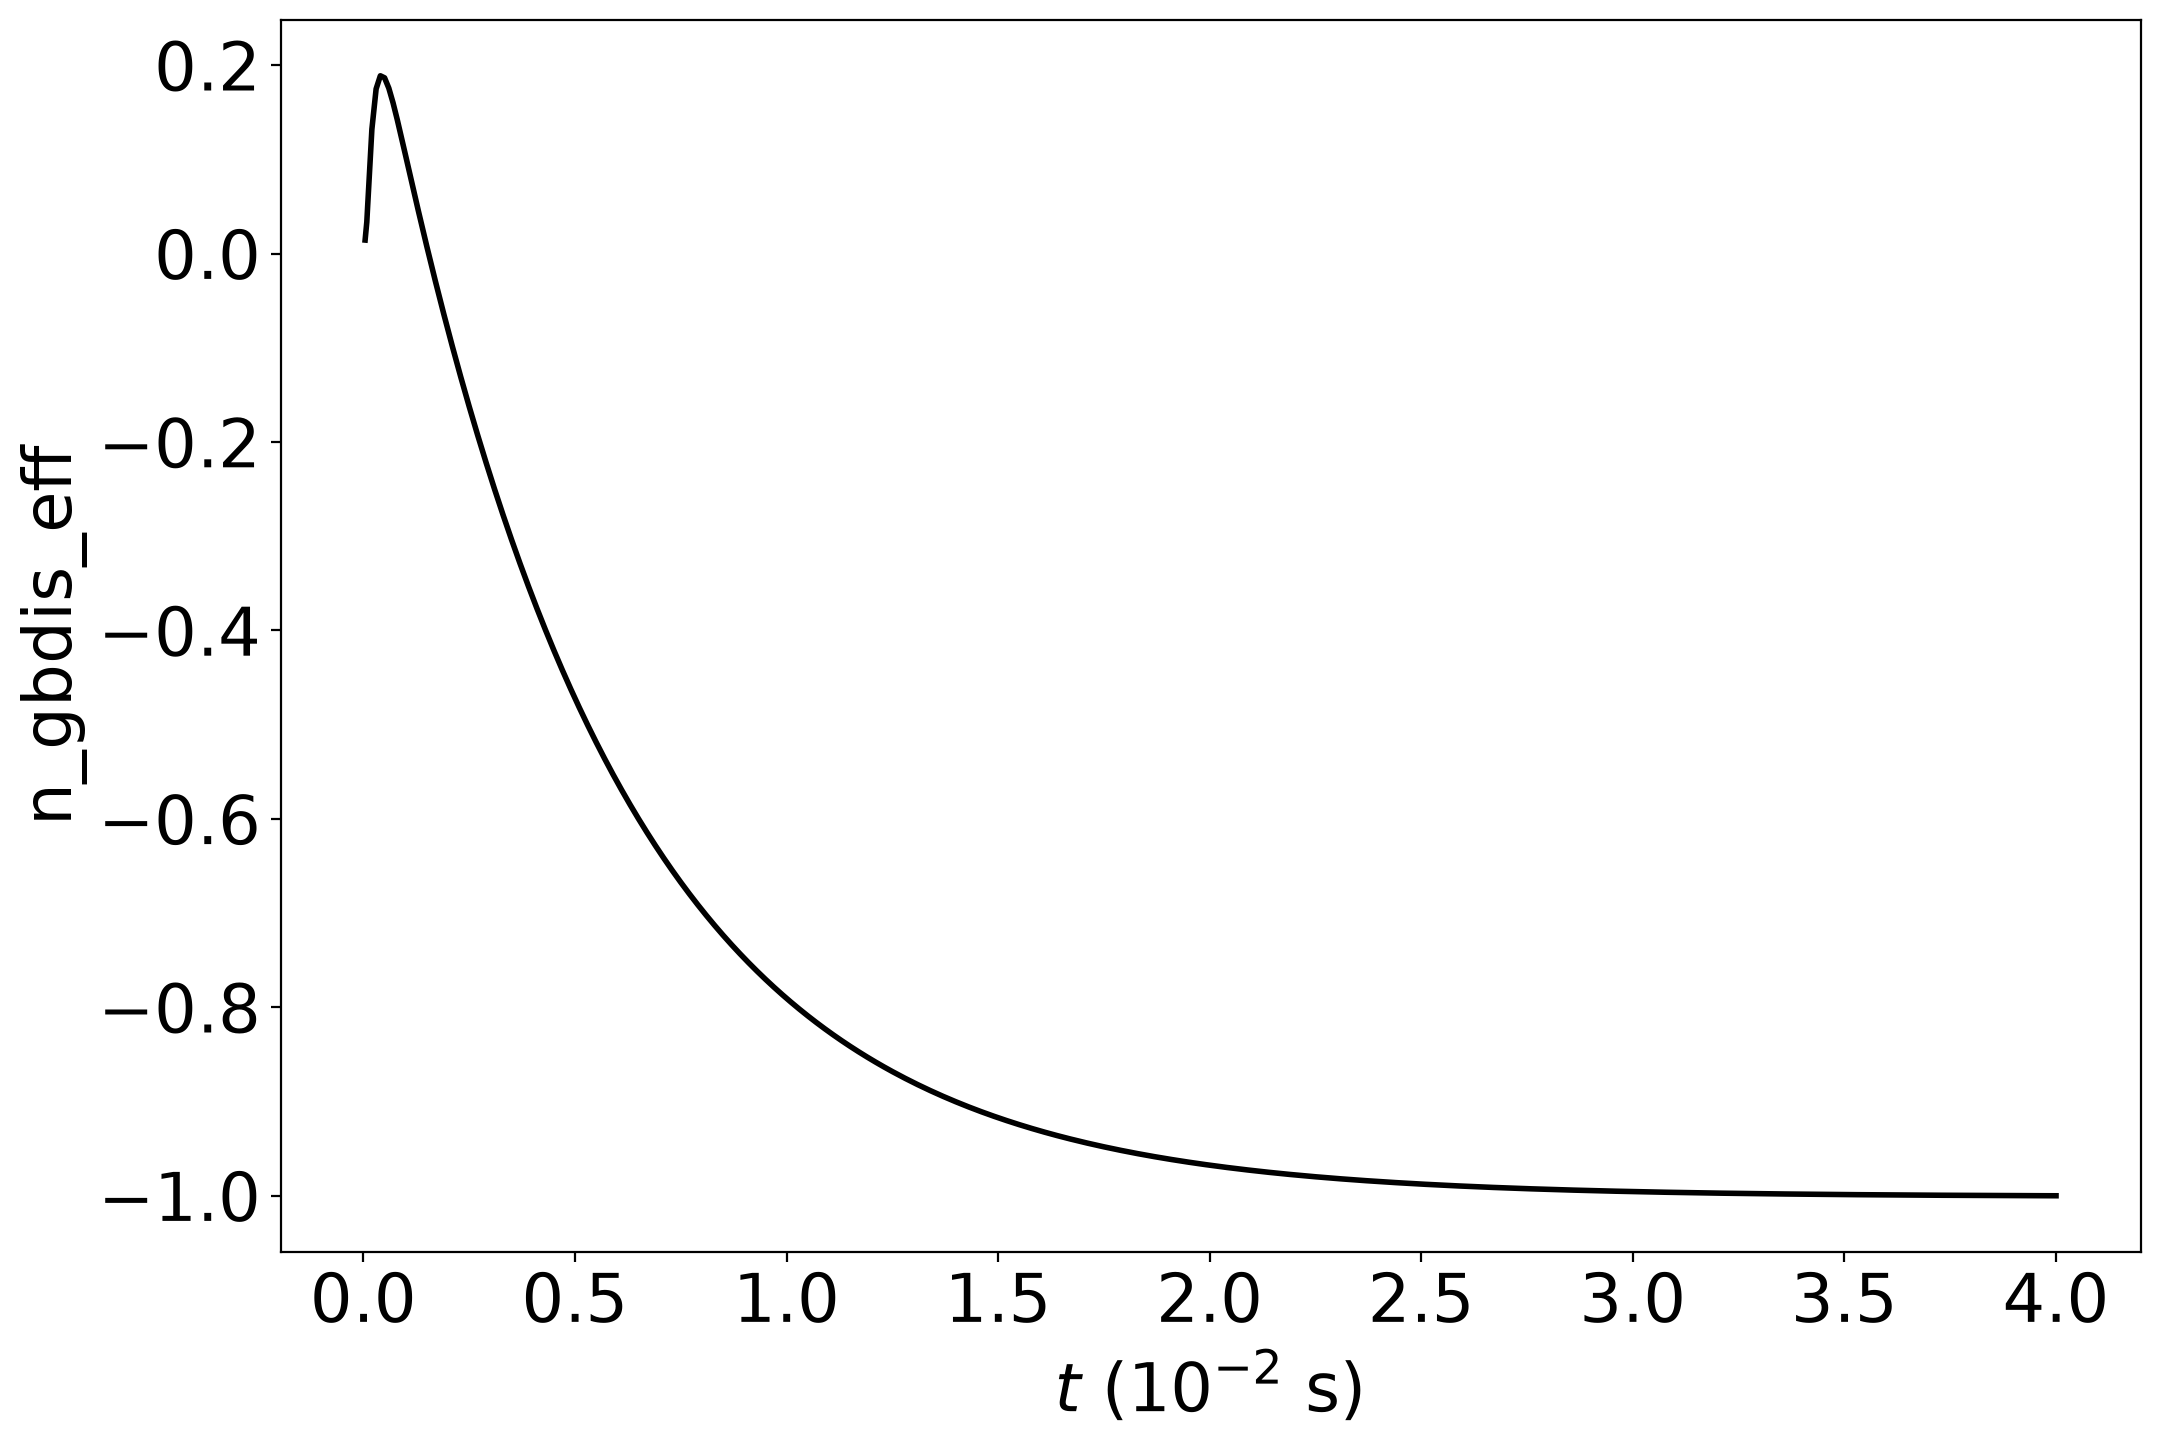

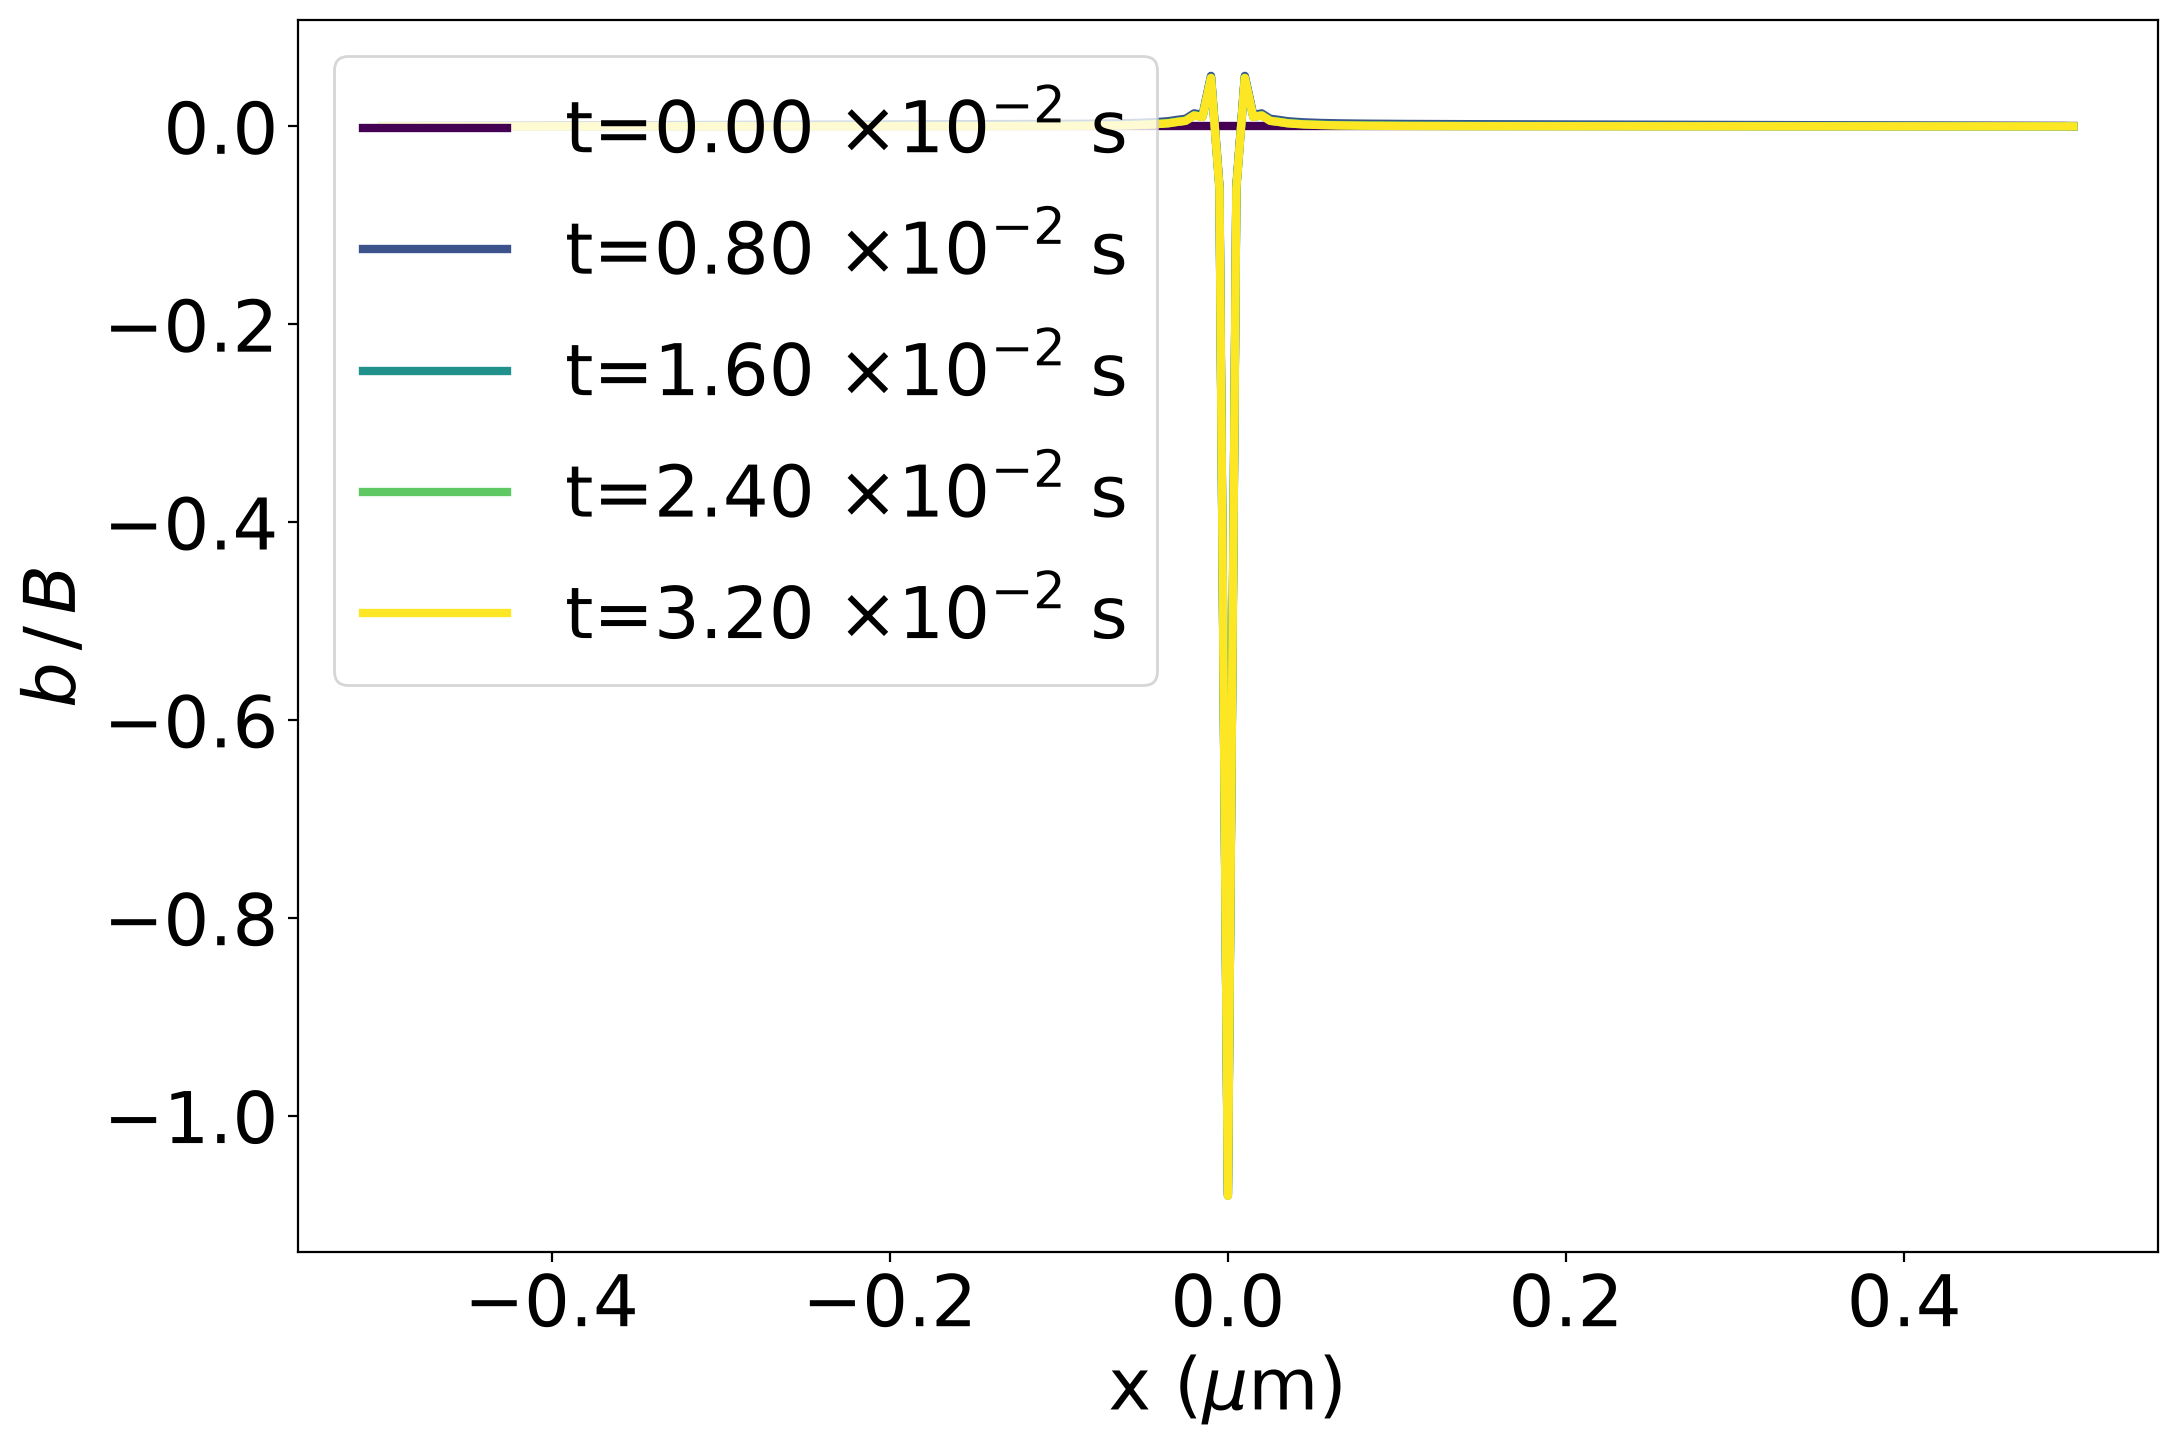

In [96]:
# Run simulation if necessary
# set simulation parameters
temp = 1200.0
tau0 = 1.e-4
lgb = 1.
gs = .01
delta = 0.005
ngbn = int(lgb/delta)
if ngbn % 2 == 0: ngbn += 1
dtmax = 1.e-3  # 6.25e-7/delta**4  # value 1.e4 for delta=0.005, 50. for PU
#grain_size = 1.0
tfin = 4.e4
niter = 50_000_000
drag = 1.e6  #500.  # 1.e6

# run special simulation with 1 immobile dislocation in pile up with drag > 1.e5
print(f"Simulation with N_gbn={ngbn}, grain_size={gs}, dtmax={dtmax}")
gbdd = dd.GB_dislocations(temp=temp, tau0=tau0,
                   Ngbn=ngbn, len_gb_seg=lgb, grain_size=gs,
                   tfin=tfin, niter=niter,
                   dtmax=dtmax, drag=drag, fcrit=1.e9, 
                   Qact=95.0e3, lambda_=0.0025, Z=10.,
                   screenout=True)
pud = np.ones(1)*0.5*gs
gbdd.run_sim(pudis=pud)
gbdd.save_hdf5(f"pu1im_T{int(temp)}_H0{int(gs*100)}_L{int(lgb*10)}.h5")
gbdd.plot_time_series(['n_gbdis_eff']) # , file="ngb_T5000_L1_d025_stat.pdf")
gbdd.plot_field('bfield', fs=26, lw=3, nplot=5) # , file="gbr_T5000_L1_d025_stat.pdf")
#gbdd.plot_time_series(['timestep', 'n_gbdis_eff'])
#gbdd.plot_time_series('plastic_slip', fs=26, lw=3)
#gbdd.plot_field('displacement', fs=26, lw=4, nplot=5,
##                file=f"tau{int(tau0)}_T{int(temp)}_D{int(gs*10)}.pdf"
#               )
#gbdd.plot_field('bfield', fs=26, lw=3, nplot=5,
##                file=f"tau{int(tau0)}_T{int(temp)}_D{int(gs*10)}.pdf"
#               )



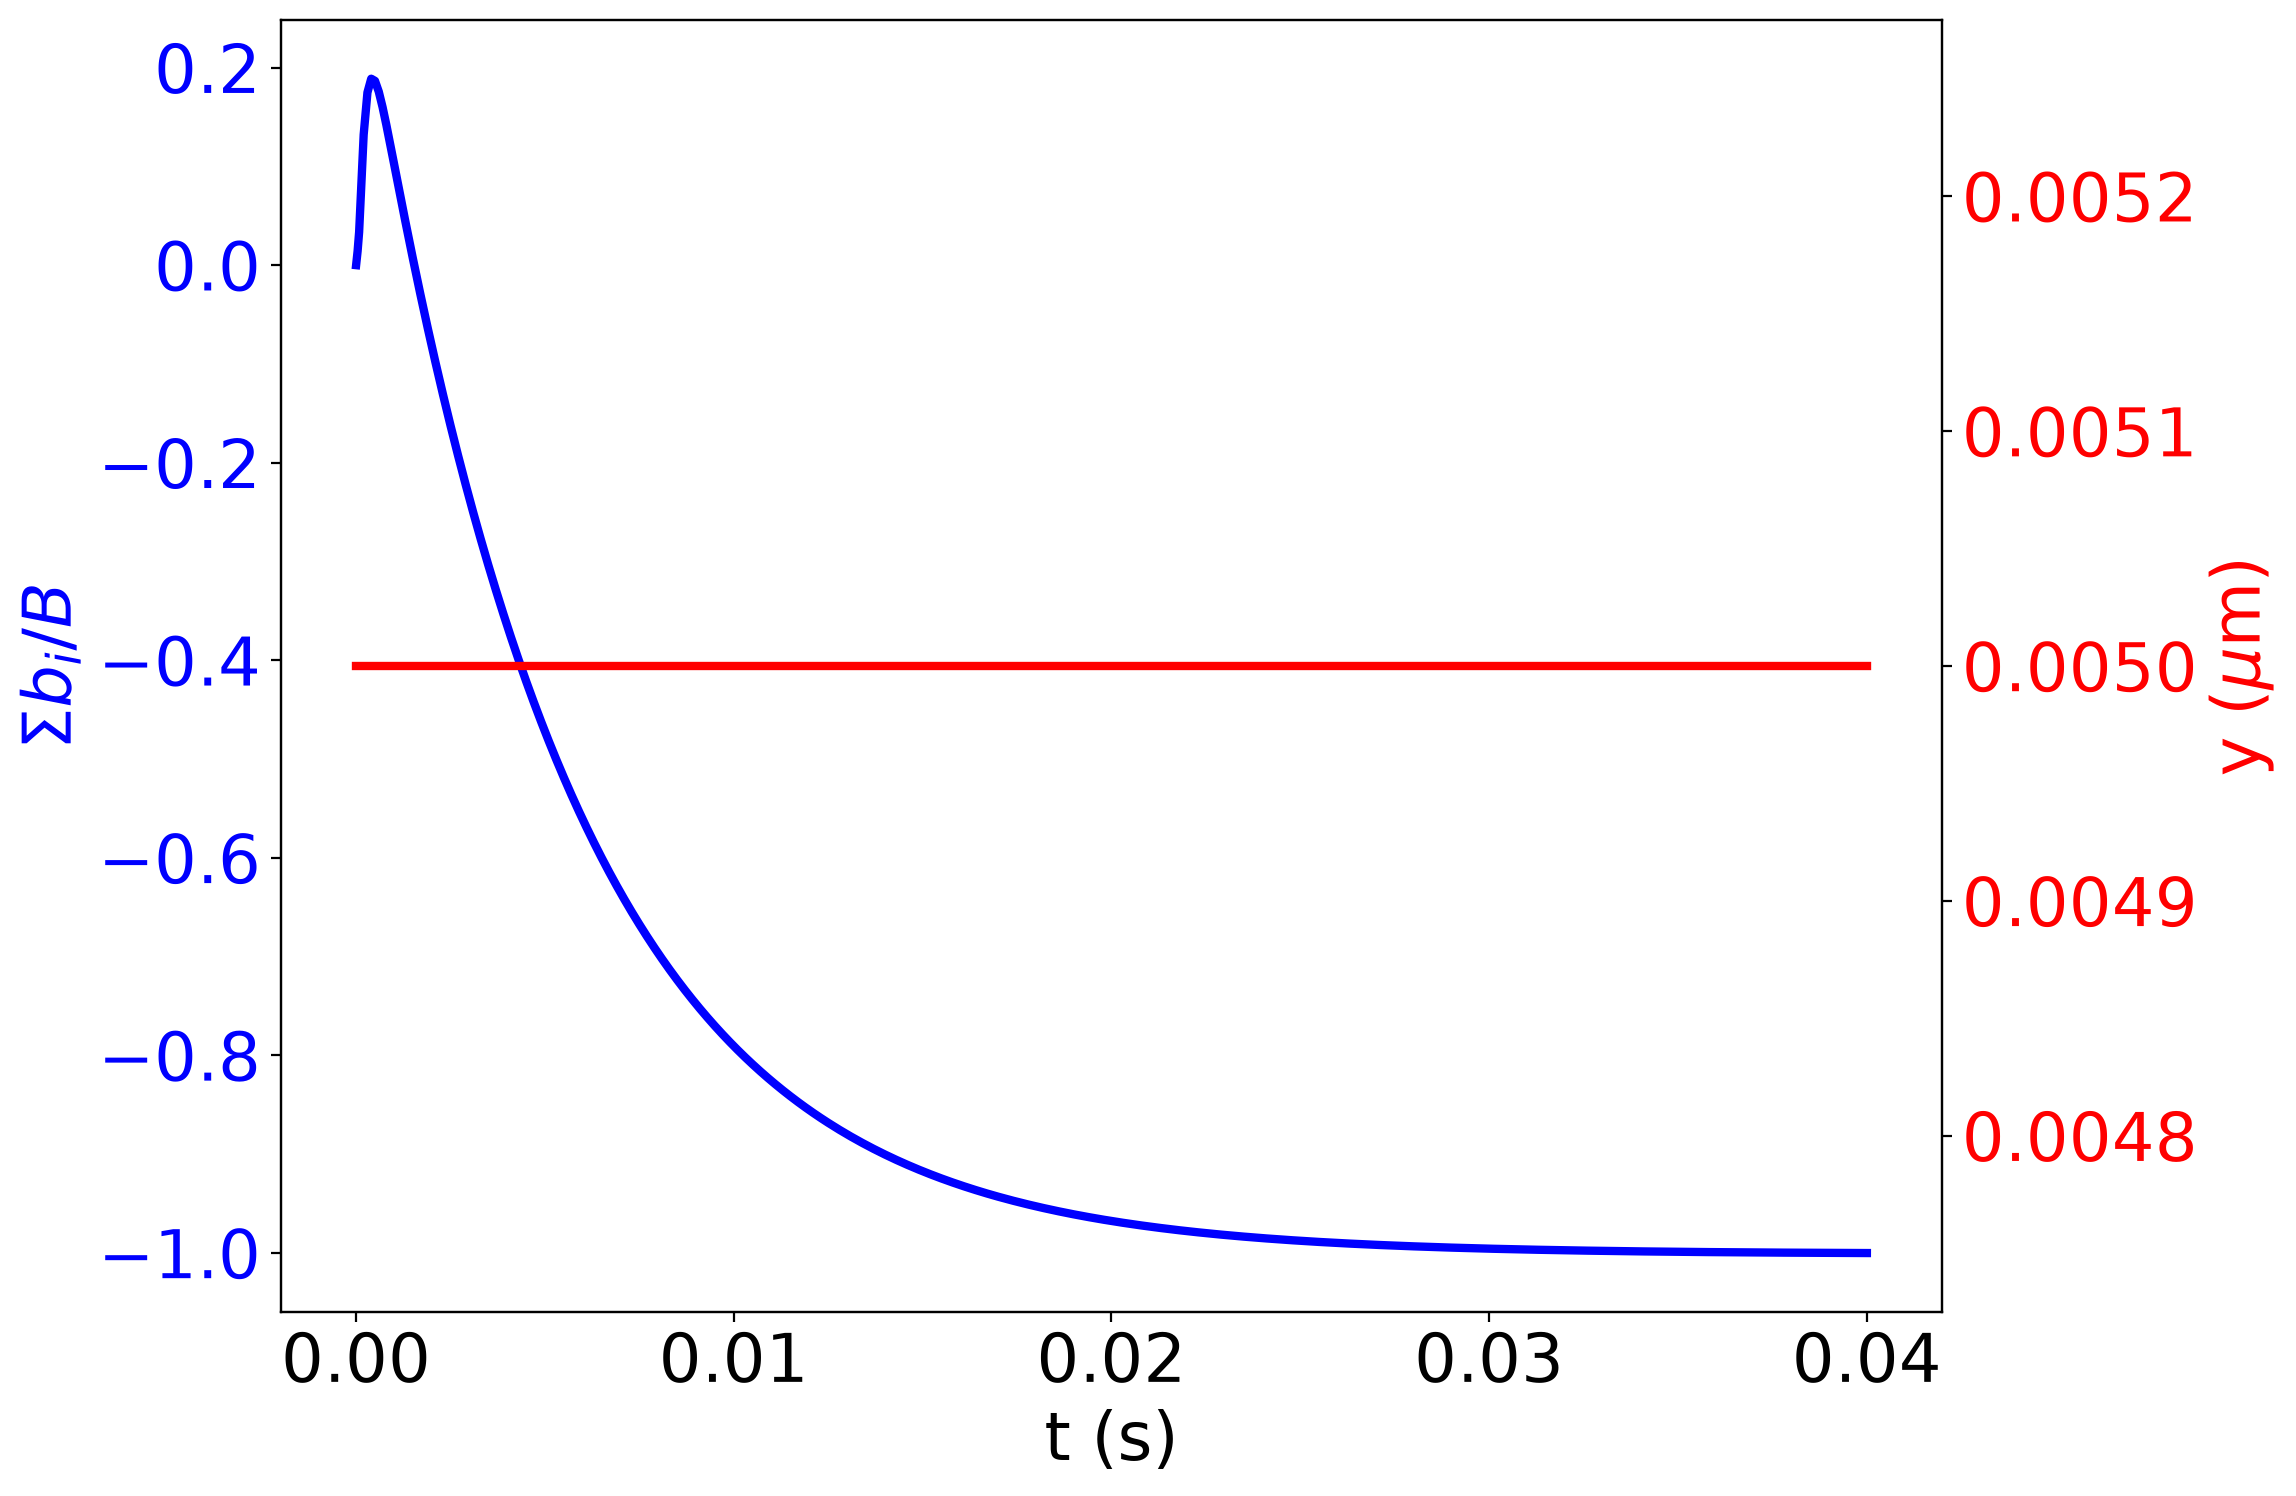

In [103]:
plt.rcParams["font.size"] = 24
fig, ax1 = plt.subplots(figsize=(12, 8), dpi=200)

# plot total B on the left axis
ax1.set_xlabel(r't (s)')
ax1.set_ylabel(r'$\Sigma b_i/B$', color="b")
ax1.plot(gbdd.sim_time[:]*1.e-6, gbdd.glob_data['n_gbdis_eff'][:], 
         'b-', lw=3)
ax1.tick_params(axis="y", labelcolor="b")

# Create a second axes sharing the same x-axis
ax2 = ax1.twinx()

# Second plot on the right axis
ax2.set_ylabel(r"y ($\mu$m)", color="r")
ax2.plot(gbdd.sim_time[:]*1.e-6, gbdd.pu_dis['position'][:], 
         'r-', lw=3)
ax2.tick_params(axis="y", labelcolor="r")

# Adjust layout to prevent label clipping
fig.tight_layout()
#plt.savefig("pu1-relax-totalB_y.pdf", dpi=300)
plt.show()

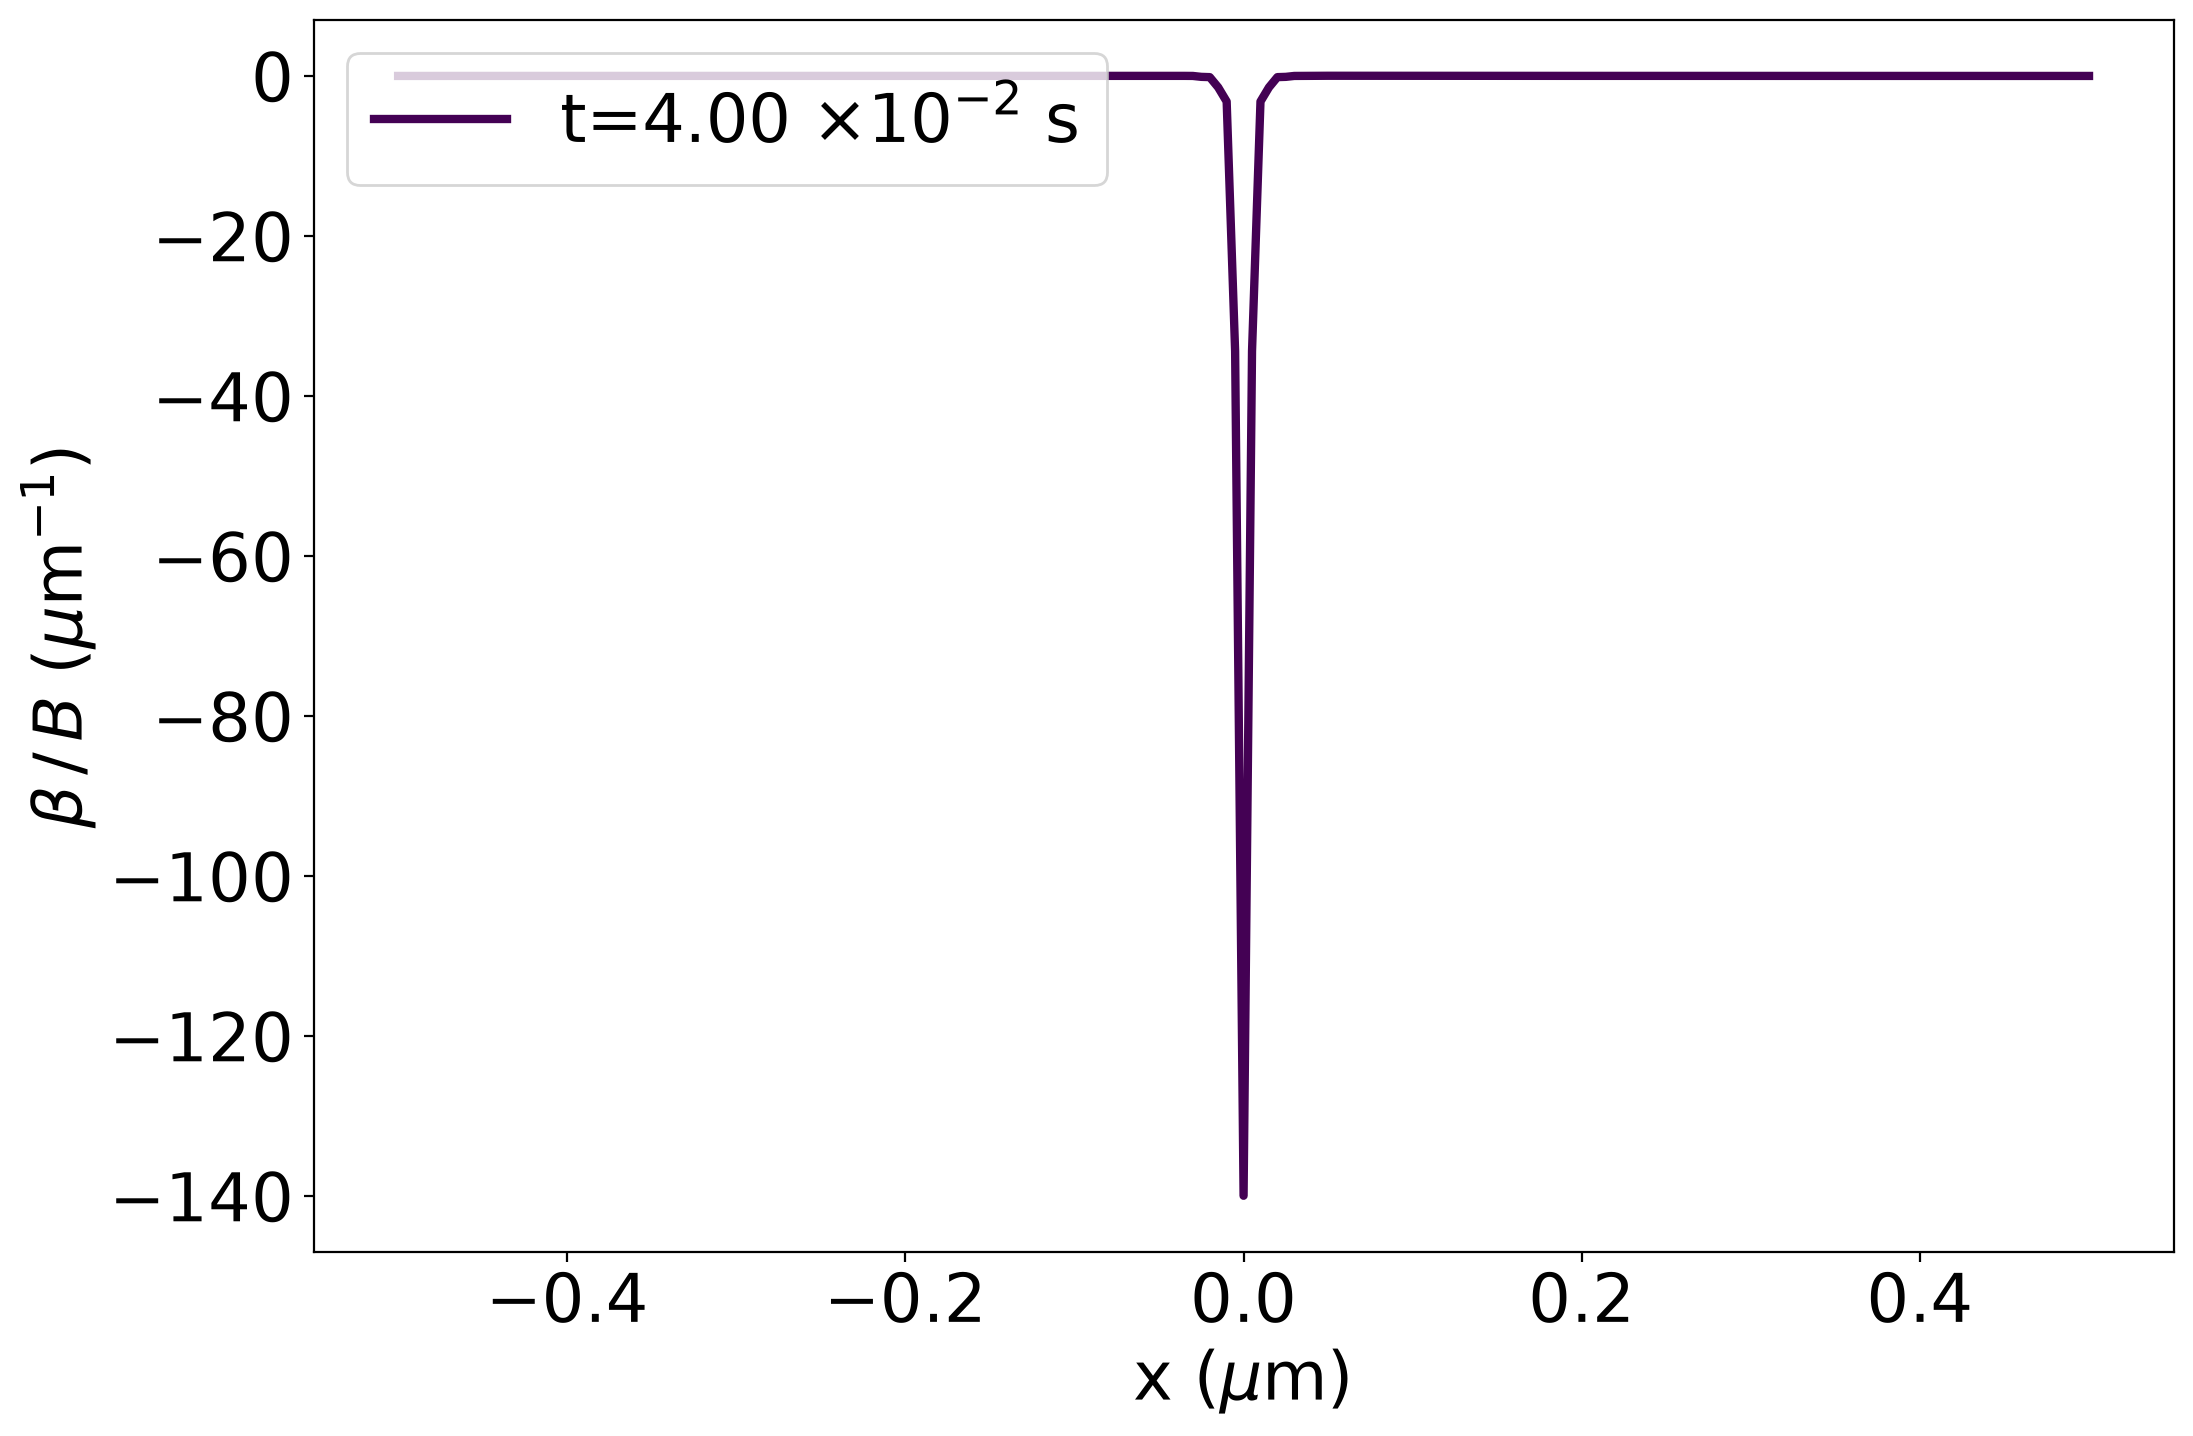

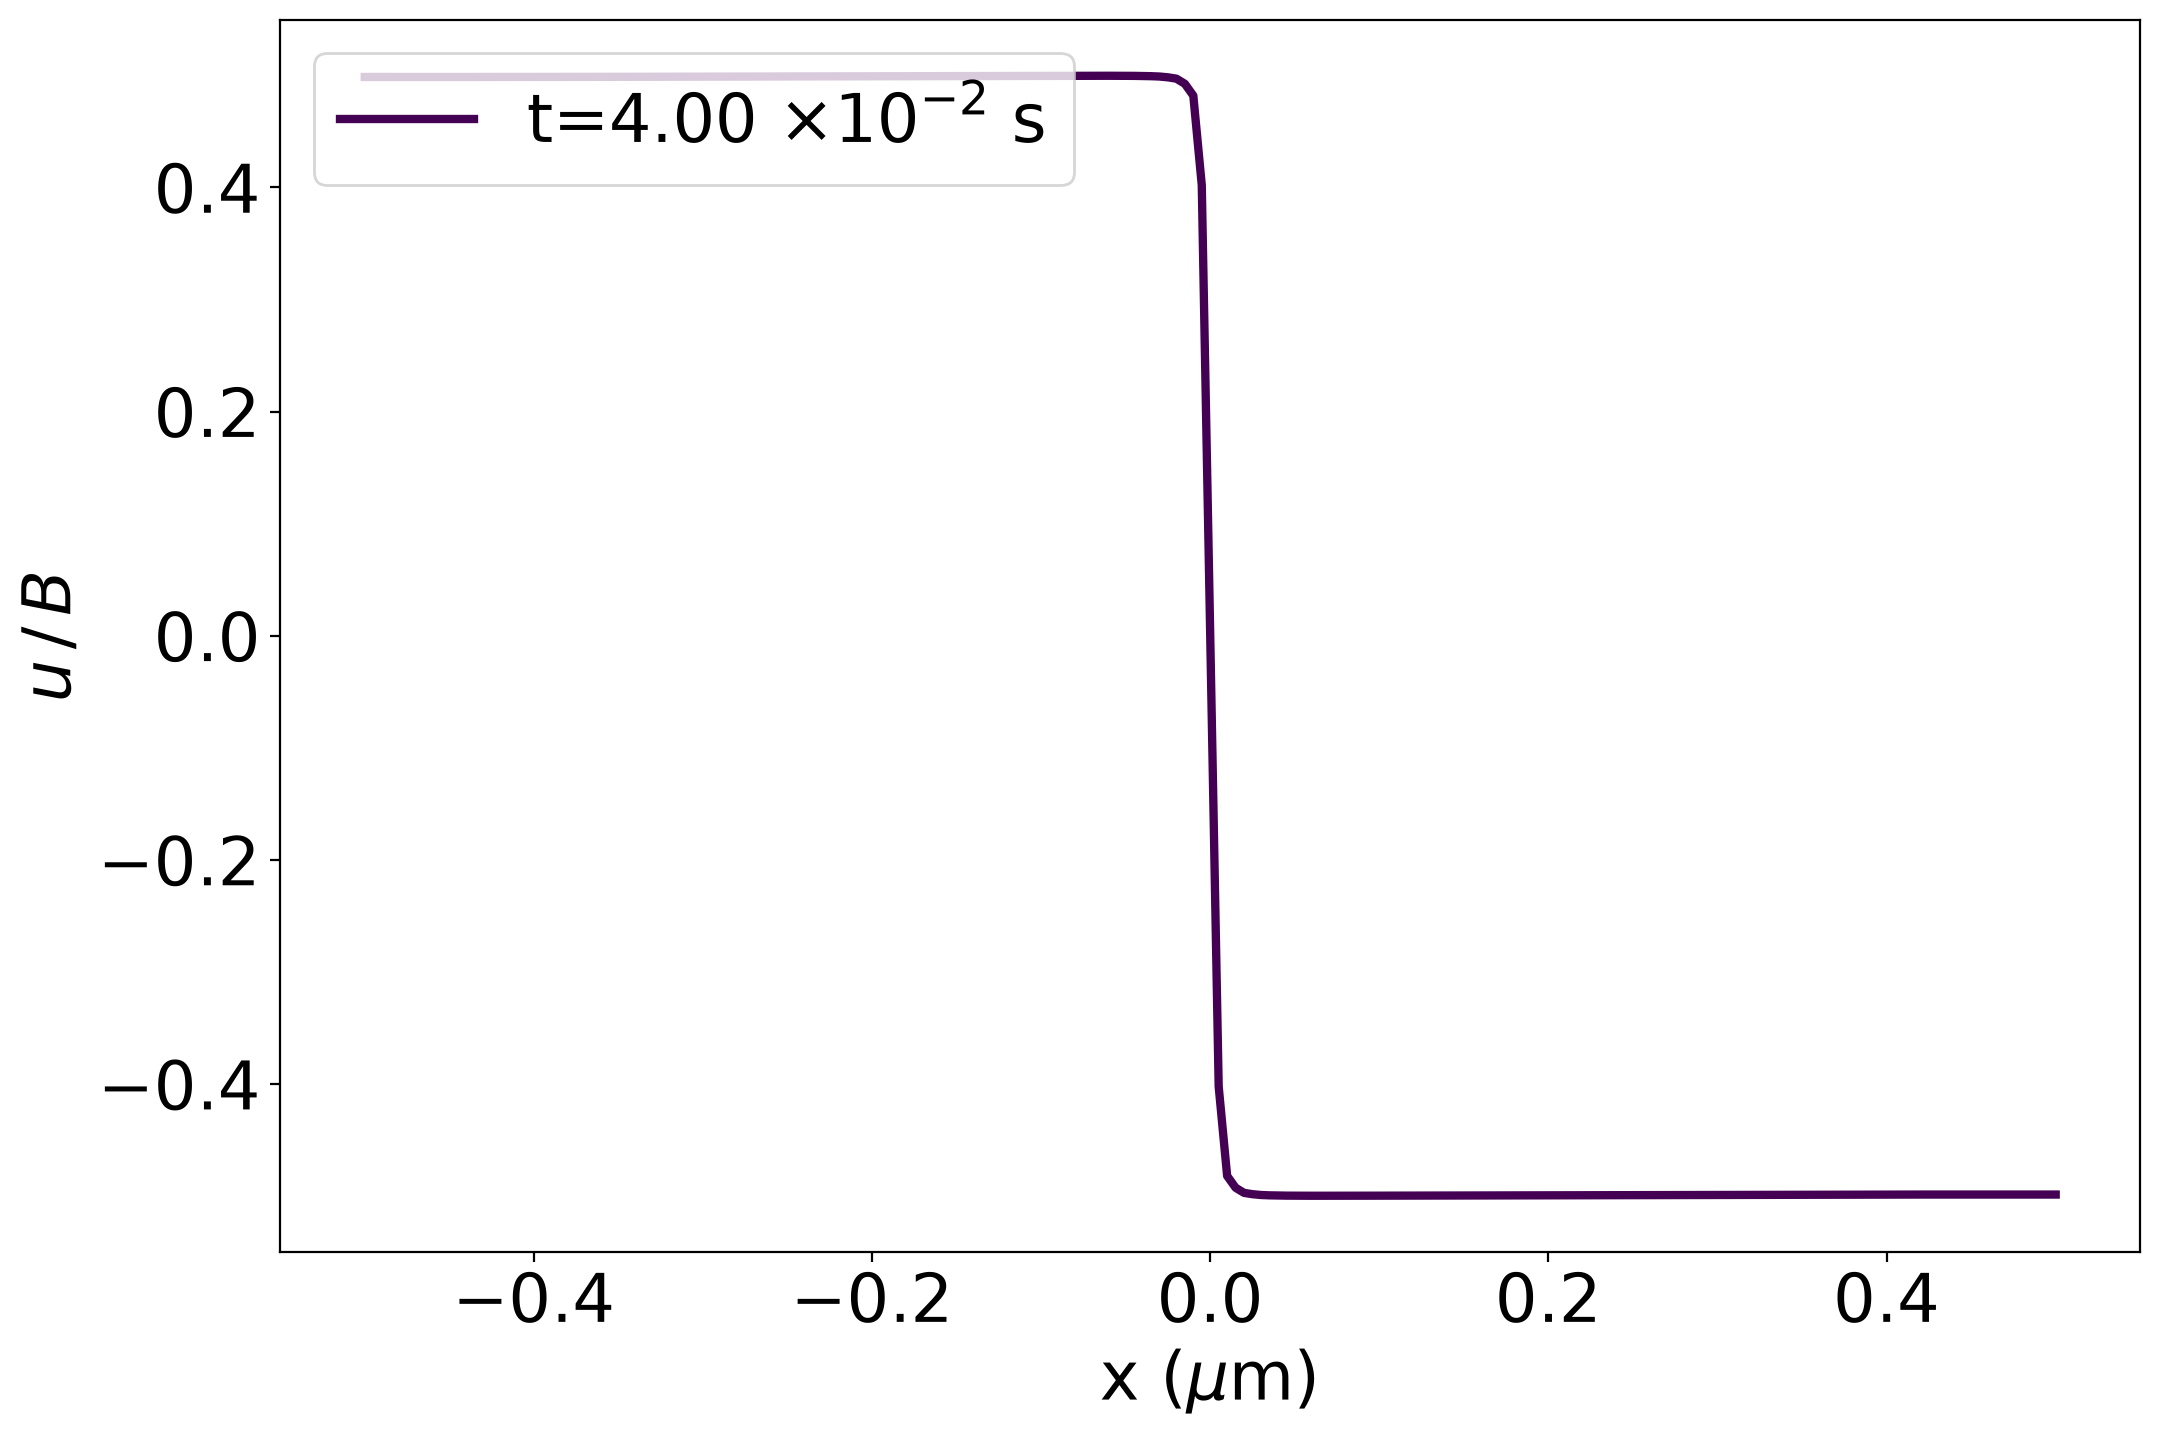

In [98]:
gbdd.plot_field("beta", times=[175],
                lw=3,
                #file="pu1_relaxed_bfield.pdf"
               )
gbdd.plot_field("displacement", times=[175],
                lw=3,
               #file="pu1_relaxed_disp.pdf"
               )

In [19]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=4, lam=0.003

array([-0.97885415, -0.9788618 , -0.9788239 , -0.97904954, -0.97777807,
       -0.97858847, -0.9786246 , -0.97867479, -0.97872904, -0.98190365])

In [22]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=5, lam=0.003

array([-0.9874069 , -0.98740477, -0.98741366, -0.98736848, -0.98761073,
       -0.98736673, -0.98737568, -0.98738834, -0.98739976, -0.99032878])

In [24]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=6, lam=0.003

array([-0.99218589, -0.99216674, -0.99213528, -0.9921105 , -0.99210314,
       -0.99211193, -0.99208303, -0.99221765, -0.9915655 , -0.99524272])

In [26]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.003

array([-0.99913911, -0.99905281, -0.99900732, -0.99901812, -0.99899056,
       -0.99910446, -0.99850876, -1.00147933, -0.99972843, -1.00078504])

In [28]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=20, lam=0.003

array([-1.0019583 , -1.00194505, -1.0019604 , -1.00190995, -1.00214409,
       -1.00101328, -1.00209626, -1.00206122, -1.00200577, -1.00491958])

In [30]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.002, delta=0.004

array([-0.99733203, -0.99733766, -0.99734139, -0.99734259, -0.99734015,
       -0.99736049, -0.99718458, -0.9973521 , -0.99734972, -1.00008541])

In [35]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.002, delta=0.005

array([-0.99735885, -0.99735878, -0.99735872, -0.99735867, -0.99735863,
       -0.99735861, -0.99735861, -0.99735865, -0.99735865, -0.99989907])

In [39]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.01

array([-1.00981726, -1.00981752, -1.00981778, -1.00981804, -1.00981831,
       -1.00981857, -1.00981883, -1.00981909, -1.00981935, -1.014408  ])

In [42]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.005

array([-1.00232795, -1.0023281 , -1.00232828, -1.00232843, -1.00232865,
       -1.00232878, -1.00232905, -1.0023291 , -1.00232953, -1.00564659])

In [45]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.0025

array([-0.99821355, -0.99821282, -0.99821504, -0.99820475, -0.99826945,
       -0.99811695, -0.998158  , -0.99817963, -0.99819311, -1.00101697])

In [48]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.0001

array([-0.99550036, -0.99519409, -0.99527447, -0.99533024, -0.99536772,
       -0.99539237, -0.99540833, -0.99542024, -0.99542955, -0.99808271])

In [51]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=40, lam=0.0025

array([-1.00182397, -1.00183523, -1.00184371, -1.0018484 , -1.00184777,
       -1.00184955, -1.00184162, -1.00189078, -1.00159839, -1.00452941])

In [54]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.01, detla=0.02

array([-1.0111619 , -1.01116214, -1.01116238, -1.01116262, -1.01116287,
       -1.01116311, -1.01116335, -1.01116359, -1.01116383, -1.01531888])

In [59]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.002, delta=0.02

array([-0.99767275, -0.99768414, -0.99767247, -0.99768503, -0.99767231,
       -0.99768539, -0.997673  , -0.99768487, -0.99767419, -1.00003209])

In [75]:
gbdd.glob_data['n_gbdis_eff'][-10:] # Z=10, lam=0.0025, delta=0.02

array([-0.99916342, -0.99916357, -0.99916373, -0.99916388, -0.99916404,
       -0.99916419, -0.99916435, -0.9991645 , -0.99916466, -1.00164083])

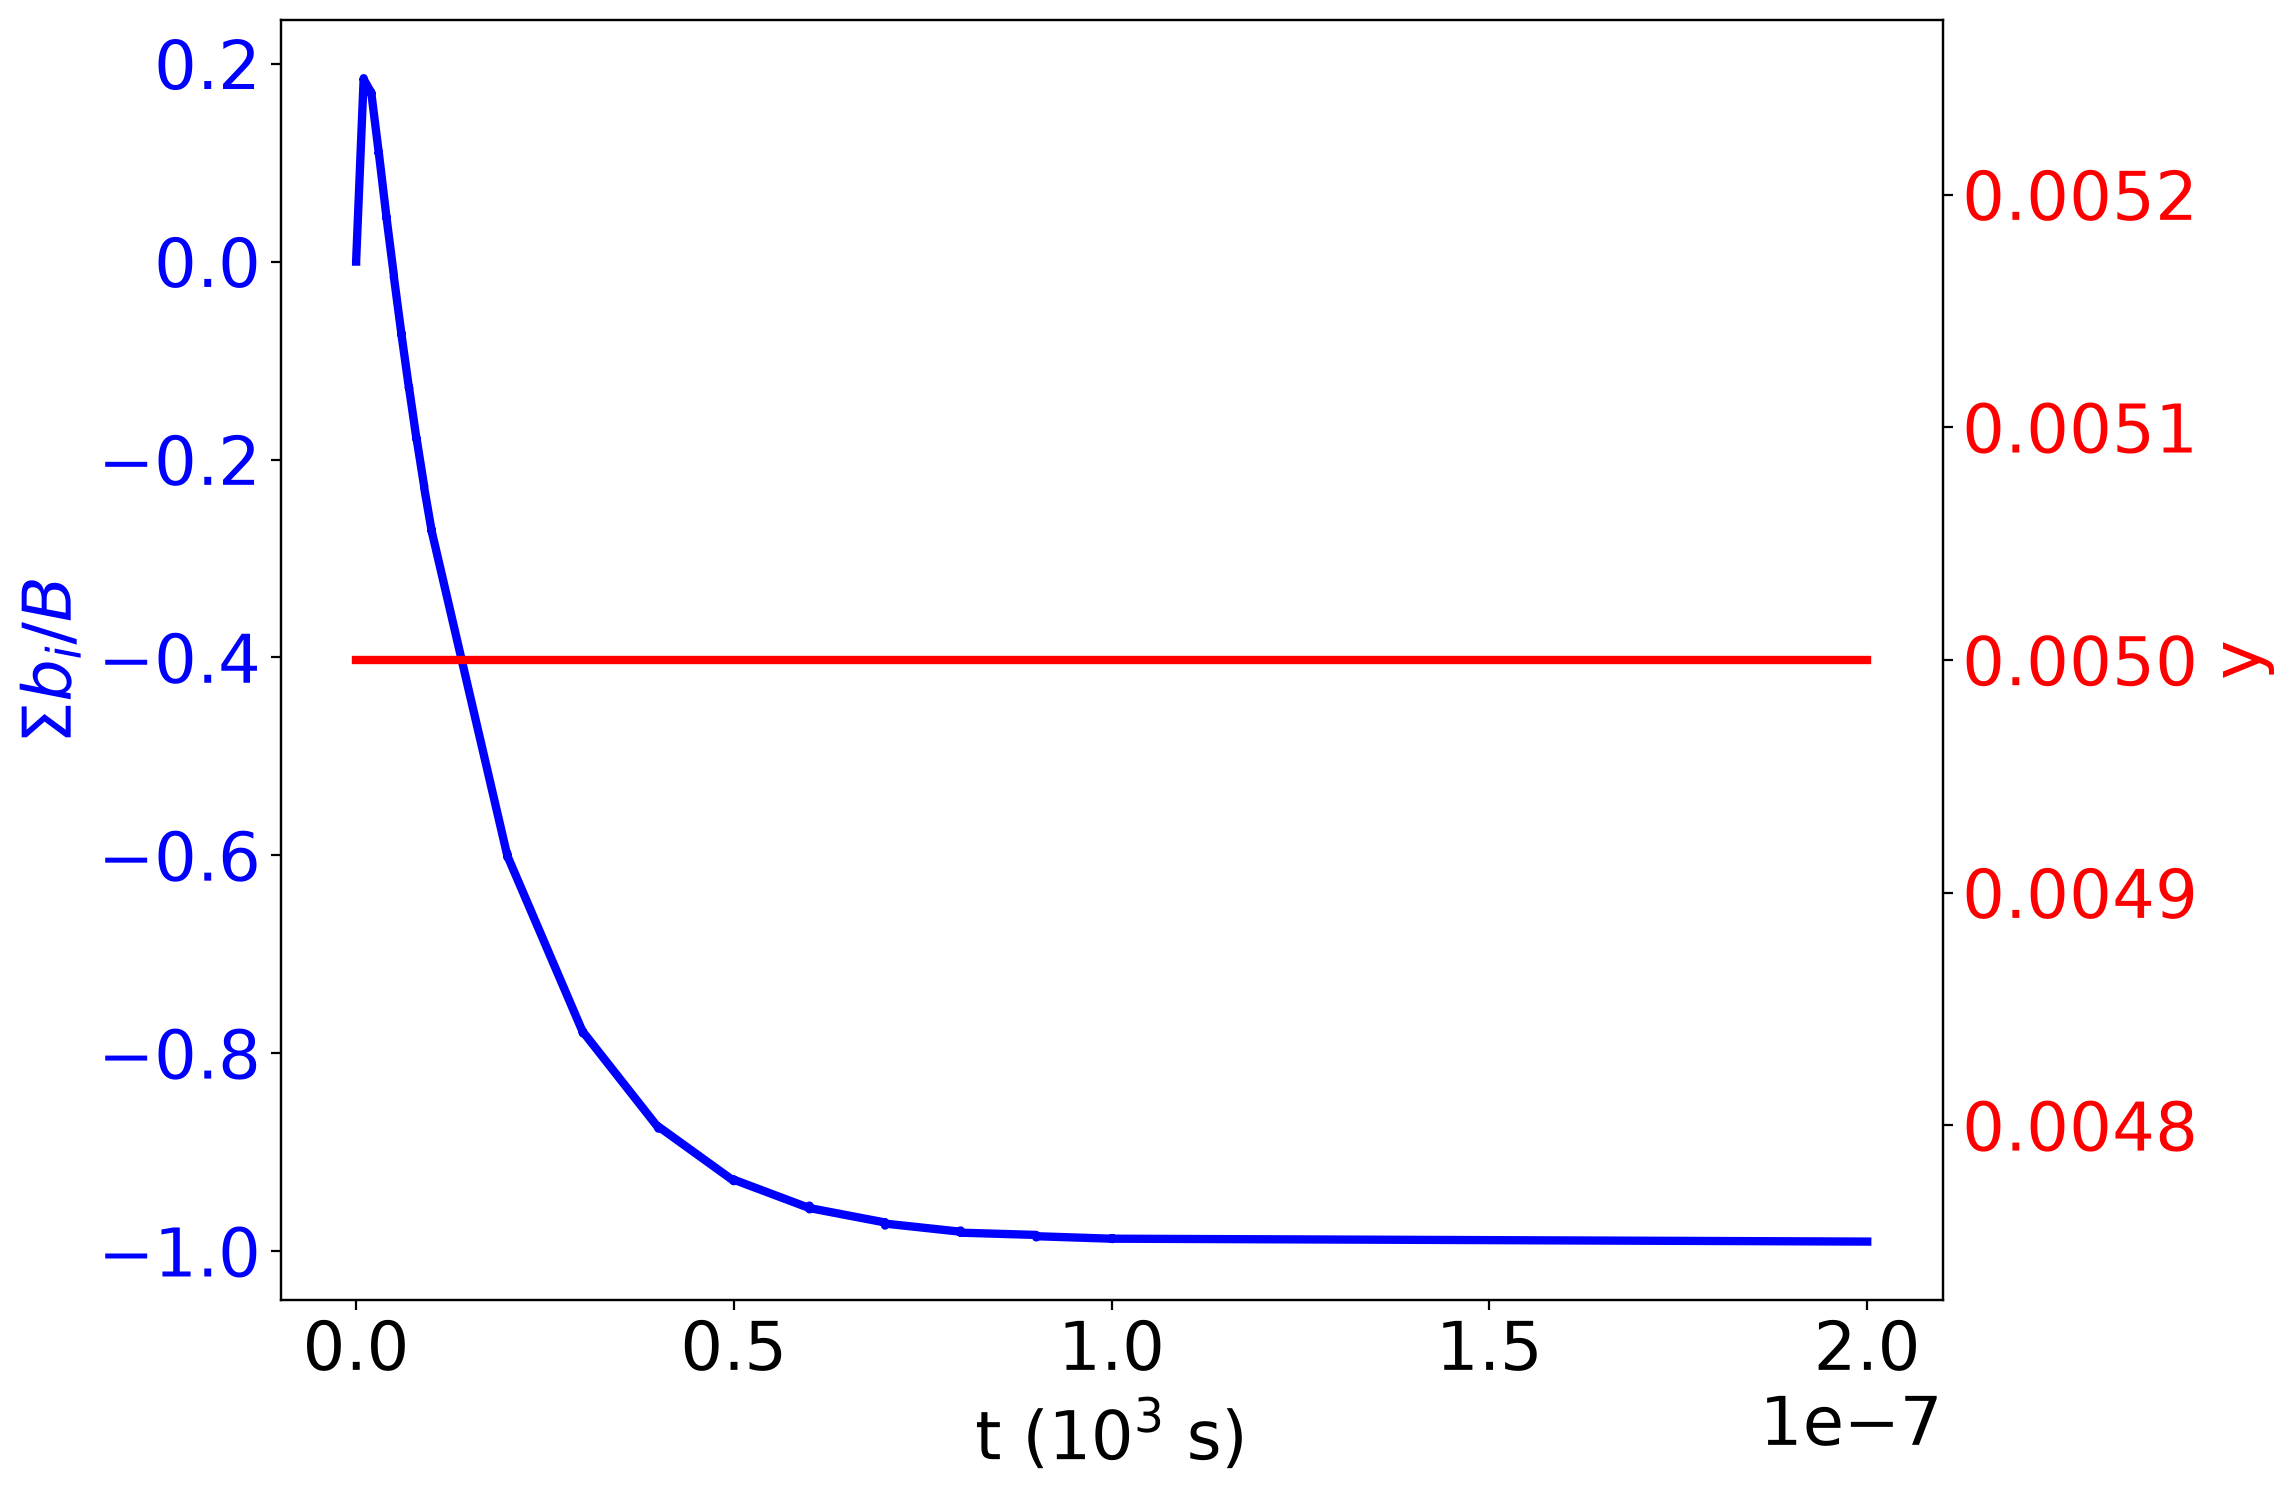

In [9]:
gbT5 = dd.GB_dislocations(from_file="../data/pu1_T5000_H050_L10.h5")
fig, ax1 = plt.subplots(figsize=(12, 8), dpi=200)

# plot total B on the left axis
ax1.set_xlabel(r't (10$^3$ s)')
ax1.set_ylabel(r'$\Sigma b_i/B$', color="b")
ax1.plot(gbT5.sim_time[:]*1.e-9, gbT5.glob_data['n_gbdis_eff'][:], 
         'b-', lw=3)
ax1.tick_params(axis="y", labelcolor="b")

# Create a second axes sharing the same x-axis
ax2 = ax1.twinx()

# Second plot on the right axis
ax2.set_ylabel("y", color="r")
ax2.plot(gbT5.sim_time[:]*1.e-9, gbT5.pu_dis['position'][:], 
         'r-', lw=3)
ax2.tick_params(axis="y", labelcolor="r")

# Adjust layout to prevent label clipping
fig.tight_layout()
#plt.savefig("pu1-relax-totalB_y.pdf", dpi=300)
plt.show()

In [ ]:
gbT5.plot_field("bfield", times=[150, 155, 158, 159, 160],
                lw=3,
                file="pu1_relax_bfield_T5000.pdf"
               )
gbT5.plot_field("displacement", times=[150, 155, 158, 159, 160],
                lw=3,
                file="pu1_relax_disp_T5000.pdf"
               )